# Calibration (Reliability) Plot

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Compares predicted probabilities with observed event frequencies, bin by bin. It shows whether a model's '30% risk' really means that 30 of 100 such patients have the event.

## When to use

- Evaluate clinical risk scores and any model whose probabilities drive decisions
- Check models after recalibration (Platt or isotonic scaling)
- Use alongside ROC/AUC, because a model can rank well and still be badly calibrated

## Avoid when

- Only the ranking matters, not the probabilities
- The sample is so small that each bin holds only a few cases (use fewer bins or a smoothed curve)

## Alternatives

- Brier score (a single number)
- Calibration belt
- Decision curve analysis

## Design tips

- Show the perfect-calibration diagonal
- Add a histogram of predicted probabilities beneath, so readers see where the data actually lies

## Example

A well-calibrated logistic regression versus an over-confident Gaussian naive Bayes on the same data.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.calibration import calibration_curve

### Data

In [2]:
X, y = make_classification(n_samples=8000, n_features=20, n_informative=4, n_redundant=6,
                           random_state=2)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.5, random_state=2)
models = {"Logistic regression": LogisticRegression(max_iter=1000), "Naive Bayes": GaussianNB()}
probs = {name: m.fit(X_tr, y_tr).predict_proba(X_te)[:, 1] for name, m in models.items()}
df = pd.DataFrame({"y_true": y_te, **probs})
df.head()

,y_true,Logistic regression,Naive Bayes
0,1,0.992765,0.867934
1,1,0.804435,0.737858
2,0,0.101986,0.049864
3,1,0.407775,0.408716
4,1,0.919437,0.793749


### Plot

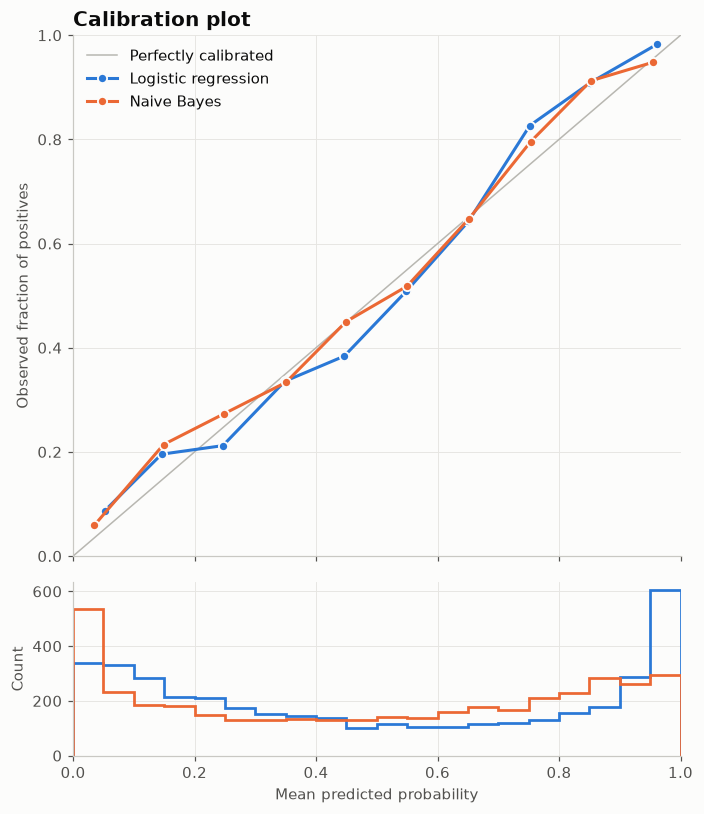

In [3]:
fig, (ax, axh) = plt.subplots(2, 1, figsize=(6.5, 7.5), height_ratios=[3, 1], sharex=True)
ax.plot([0, 1], [0, 1], color=GRAY, linewidth=1, label="Perfectly calibrated")
bins = np.linspace(0, 1, 21)
for i, name in enumerate(probs):
    frac_pos, mean_pred = calibration_curve(df["y_true"], df[name], n_bins=10)
    ax.plot(mean_pred, frac_pos, "o-", color=PALETTE[i], markersize=6, label=name,
            markeredgecolor="#fcfcfb", markeredgewidth=1.2)
    axh.hist(df[name], bins=bins, histtype="step", color=PALETTE[i], linewidth=1.8)
ax.set_ylabel("Observed fraction of positives")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_title("Calibration plot")
ax.legend(loc="upper left")
axh.set_xlabel("Mean predicted probability"); axh.set_ylabel("Count")
fig.tight_layout()
plt.show()

## How to read it

Points on the diagonal mean the predicted probabilities match reality. The naive Bayes S-curve is over-confident: its histogram piles up at 0 and 1.

---
Standalone script: [`calibration_plot.py`](calibration_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)